# Preanalysis

## Data Importing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings
from statsmodels.stats.diagnostic import linear_reset
import statsmodels.api as sm

plt.style.use("seaborn-v0_8-whitegrid")
filterwarnings("ignore")

In [2]:
price_history_gas_monthly1    = pd.read_csv('data/Price History_Gas_Monthly1.csv')
price_history_carbon          = pd.read_csv('data/Price History_Carbon.csv')
price_history_coal            = pd.read_csv('data/Price History_Coal.csv')
price_history_EURUSD          = pd.read_csv('data/Price History_EUR:USD.csv')
price_history_gas_storage     = pd.read_csv('data/Price History_Gas_Storage.csv')
price_history_VSTOXX          = pd.read_csv('data/Price History_VSTOXX.csv')
price_history_STOXX_utilities = pd.read_csv('data/Price History_STOXX_Utilities.csv')
de_daily                      = pd.read_csv('data/DE.csv')
fr_daily_raw                  = pd.read_csv('data/FR.csv')
norway_hydro_raw              = pd.read_csv('data/Norway_Hydro_Reservoirs.csv')

In [3]:
# DE.csv is already daily; Price and forecast columns are daily means.
de_daily['date'] = pd.to_datetime(de_daily['datetime']).dt.normalize()

price_history_electricity = (
    de_daily[['date', 'Price']]
    .rename(columns={'Price': 'price'})
)

amprion_load = (
    de_daily[['date', 'Amprion Load Forecast Mean']]
    .rename(columns={'Amprion Load Forecast Mean': 'gen'})
)

pv_wind = (
    de_daily[['date', 'PV+Wind Forecast Mean']]
    .rename(columns={'PV+Wind Forecast Mean': 'gen'})
)

price_history_electricity.head()

,date,price
0,2019-01-01,-4.297083
1,2019-01-02,25.917500
2,2019-01-03,57.716250
3,2019-01-04,49.910000
4,2019-01-05,42.180833


In [4]:
# handle standard Price History files (Close as price)
def _handle_commodities(df):
    df = df.copy()
    df['Exchange Date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['date'] = df['Exchange Date']
    df['price'] = pd.to_numeric(df['Close'], errors='coerce')
    return df[['date', 'price']]

# handle forex (mid of bid/ask)
def _handle_forex(df):
    df = df.copy()
    df['Exchange Date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['date'] = df['Exchange Date']
    df['price'] = (pd.to_numeric(df['Bid'], errors='coerce') +
                   pd.to_numeric(df['Ask'], errors='coerce')) / 2
    return df[['date', 'price']]

# handle gas storage: Full (%) as price level
def _handle_gas_storage(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['price'] = pd.to_numeric(df['Full (%)'], errors='coerce')
    return df[['date', 'price']]

# handle Norway hydro: Energy (MWh) as price level
def _handle_norway_hydro(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['Exchange Date'], dayfirst=True)
    df['price'] = pd.to_numeric(df['Energy (MWh)'], errors='coerce')
    return df[['date', 'price']]

# handle FR electricity (daily CSV, same format as DE.csv)
def _handle_fr(df):
    df = df.copy()
    df['date'] = pd.to_datetime(df['datetime'])
    df['price'] = pd.to_numeric(df['Price'], errors='coerce')
    return df[['date', 'price']]

In [5]:
price_history_gas_monthly1    = _handle_commodities(price_history_gas_monthly1)
price_history_carbon          = _handle_commodities(price_history_carbon)
price_history_coal            = _handle_commodities(price_history_coal)
price_history_EURUSD          = _handle_forex(price_history_EURUSD)
price_history_gas_storage     = _handle_gas_storage(price_history_gas_storage)
price_history_VSTOXX          = _handle_commodities(price_history_VSTOXX)
price_history_STOXX_utilities = _handle_commodities(price_history_STOXX_utilities)
fr_daily                      = _handle_fr(fr_daily_raw)
norway_hydro                  = _handle_norway_hydro(norway_hydro_raw)

In [6]:
for name, df in [
    ('Electricity',     price_history_electricity),
    ('Gas Monthly1',    price_history_gas_monthly1),
    ('Carbon',          price_history_carbon),
    ('Coal',            price_history_coal),
    ('EUR/USD',         price_history_EURUSD),
    ('Gas Storage',     price_history_gas_storage),
    ('VSTOXX',          price_history_VSTOXX),
    ('STOXX Utilities', price_history_STOXX_utilities),
    ('FR Electricity',  fr_daily),
    ('Norway Hydro',    norway_hydro),
]:
    print(f'{name}:\n{df.isna().sum()}\n')

Electricity:
date     0
price    0
dtype: int64

Gas Monthly1:
date     0
price    1
dtype: int64

Carbon:
date     0
price    0
dtype: int64

Coal:
date     0
price    0
dtype: int64

EUR/USD:
date     0
price    0
dtype: int64

Gas Storage:
date     0
price    0
dtype: int64

VSTOXX:
date     0
price    0
dtype: int64

STOXX Utilities:
date     0
price    1
dtype: int64

FR Electricity:
date     0
price    0
dtype: int64

Norway Hydro:
date     0
price    0
dtype: int64



In [7]:
def _forward_fill_missing_calendar_days(df, date_col="date", end_date=None):
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    out = out.sort_values(date_col).set_index(date_col)

    out["is_traded"] = True

    start = out.index.min()
    end = pd.to_datetime(end_date) if end_date is not None else out.index.max()

    full_idx = pd.date_range(start, end, freq="D")
    out = out.reindex(full_idx)
    out["is_traded"] = out["is_traded"].fillna(False)
    out["price"] = out["price"].ffill()

    out.index.name = date_col
    return out.reset_index()

In [8]:
end_date = price_history_electricity['date'].max()

price_history_gas_monthly1    = _forward_fill_missing_calendar_days(price_history_gas_monthly1,    end_date=end_date)
price_history_carbon          = _forward_fill_missing_calendar_days(price_history_carbon,          end_date=end_date)
price_history_coal            = _forward_fill_missing_calendar_days(price_history_coal,            end_date=end_date)
price_history_EURUSD          = _forward_fill_missing_calendar_days(price_history_EURUSD,          end_date=end_date)
price_history_gas_storage     = _forward_fill_missing_calendar_days(price_history_gas_storage,     end_date=end_date)
price_history_VSTOXX          = _forward_fill_missing_calendar_days(price_history_VSTOXX,          end_date=end_date)
price_history_STOXX_utilities = _forward_fill_missing_calendar_days(price_history_STOXX_utilities, end_date=end_date)
fr_daily                      = _forward_fill_missing_calendar_days(fr_daily,                      end_date=end_date)
norway_hydro                  = _forward_fill_missing_calendar_days(norway_hydro,                  end_date=end_date)

In [9]:
def _add_daily_returns(df, value_col="price"):
    """Compute log-returns on actual trading days only, then forward-fill for alignment."""
    out = df.copy()
    if "is_traded" in out.columns:
        traded = out["is_traded"]
        out.loc[traded, "return"] = np.log(out.loc[traded, value_col]).diff()
        out["return"] = out["return"].ffill()
    else:
        out["return"] = np.log(out[value_col]).diff()
    return out

In [10]:
# VSTOXX, STOXX Utilities, EUR/USD: log-returns as stationary feature
# Electricity returns are computed but NOT used in Granger (we use price levels)
price_history_electricity     = _add_daily_returns(price_history_electricity)
price_history_gas_monthly1    = _add_daily_returns(price_history_gas_monthly1)
price_history_carbon          = _add_daily_returns(price_history_carbon)
price_history_coal            = _add_daily_returns(price_history_coal)
price_history_EURUSD          = _add_daily_returns(price_history_EURUSD)
price_history_VSTOXX          = _add_daily_returns(price_history_VSTOXX)
price_history_STOXX_utilities = _add_daily_returns(price_history_STOXX_utilities)
fr_daily                      = _add_daily_returns(fr_daily)
amprion_load                  = _add_daily_returns(amprion_load, value_col='gen')
pv_wind                       = _add_daily_returns(pv_wind,      value_col='gen')

In [11]:
# Gas, Coal, Carbon: log(price) for use in cointegration / levels regression
for df in [price_history_gas_monthly1, price_history_carbon, price_history_coal]:
    df['log_price'] = np.log(df['price'].clip(lower=1e-6))

In [12]:
# France electricity: lagged FR price level as predictor (avoids log-return redundancy with DE)
# FR feature is lagged to avoid simultaneity with DE price
fr_daily['feature'] = fr_daily['price'].shift(1)

In [13]:
def _seasonal_deviation(df, value_col='price', period='doy', date_col='date'):
    """
    Deviation from seasonal norm (grouped mean) and z-score standardized level.
    period: 'doy' (day of year, daily data) or 'week' (ISO week, weekly data)
    The resulting 'return' column carries the stationary seasonal-deviation series
    for alignment with the existing Granger infrastructure.
    """
    out = df.copy()
    out[date_col] = pd.to_datetime(out[date_col])
    if period == 'week':
        out['_period'] = out[date_col].dt.isocalendar().week.astype(int)
    else:
        out['_period'] = out[date_col].dt.dayofyear
    stats = out.groupby('_period')[value_col].agg(['mean', 'std'])
    stats.columns = ['_s_mean', '_s_std']
    out = out.join(stats, on='_period')
    out['seasonal_dev']        = out[value_col] - out['_s_mean']
    out['standardized_level']  = out['seasonal_dev'] / out['_s_std'].replace(0, np.nan)
    out['return']              = out['standardized_level'].diff()   # first-difference of z-score → stationary for Granger
    return out.drop(columns=['_period', '_s_mean', '_s_std'])

# Gas storage: daily fill percentage — deviation from day-of-year seasonal norm
price_history_gas_storage = _seasonal_deviation(
    price_history_gas_storage, value_col='price', period='doy'
)

In [14]:
# Norway hydro: weekly reservoir level — deviation from ISO-week seasonal norm
# (Data covers 2026 only; seasonal norm is computed within the available window)
norway_hydro = _seasonal_deviation(
    norway_hydro, value_col='price', period='week'
)

## Overview

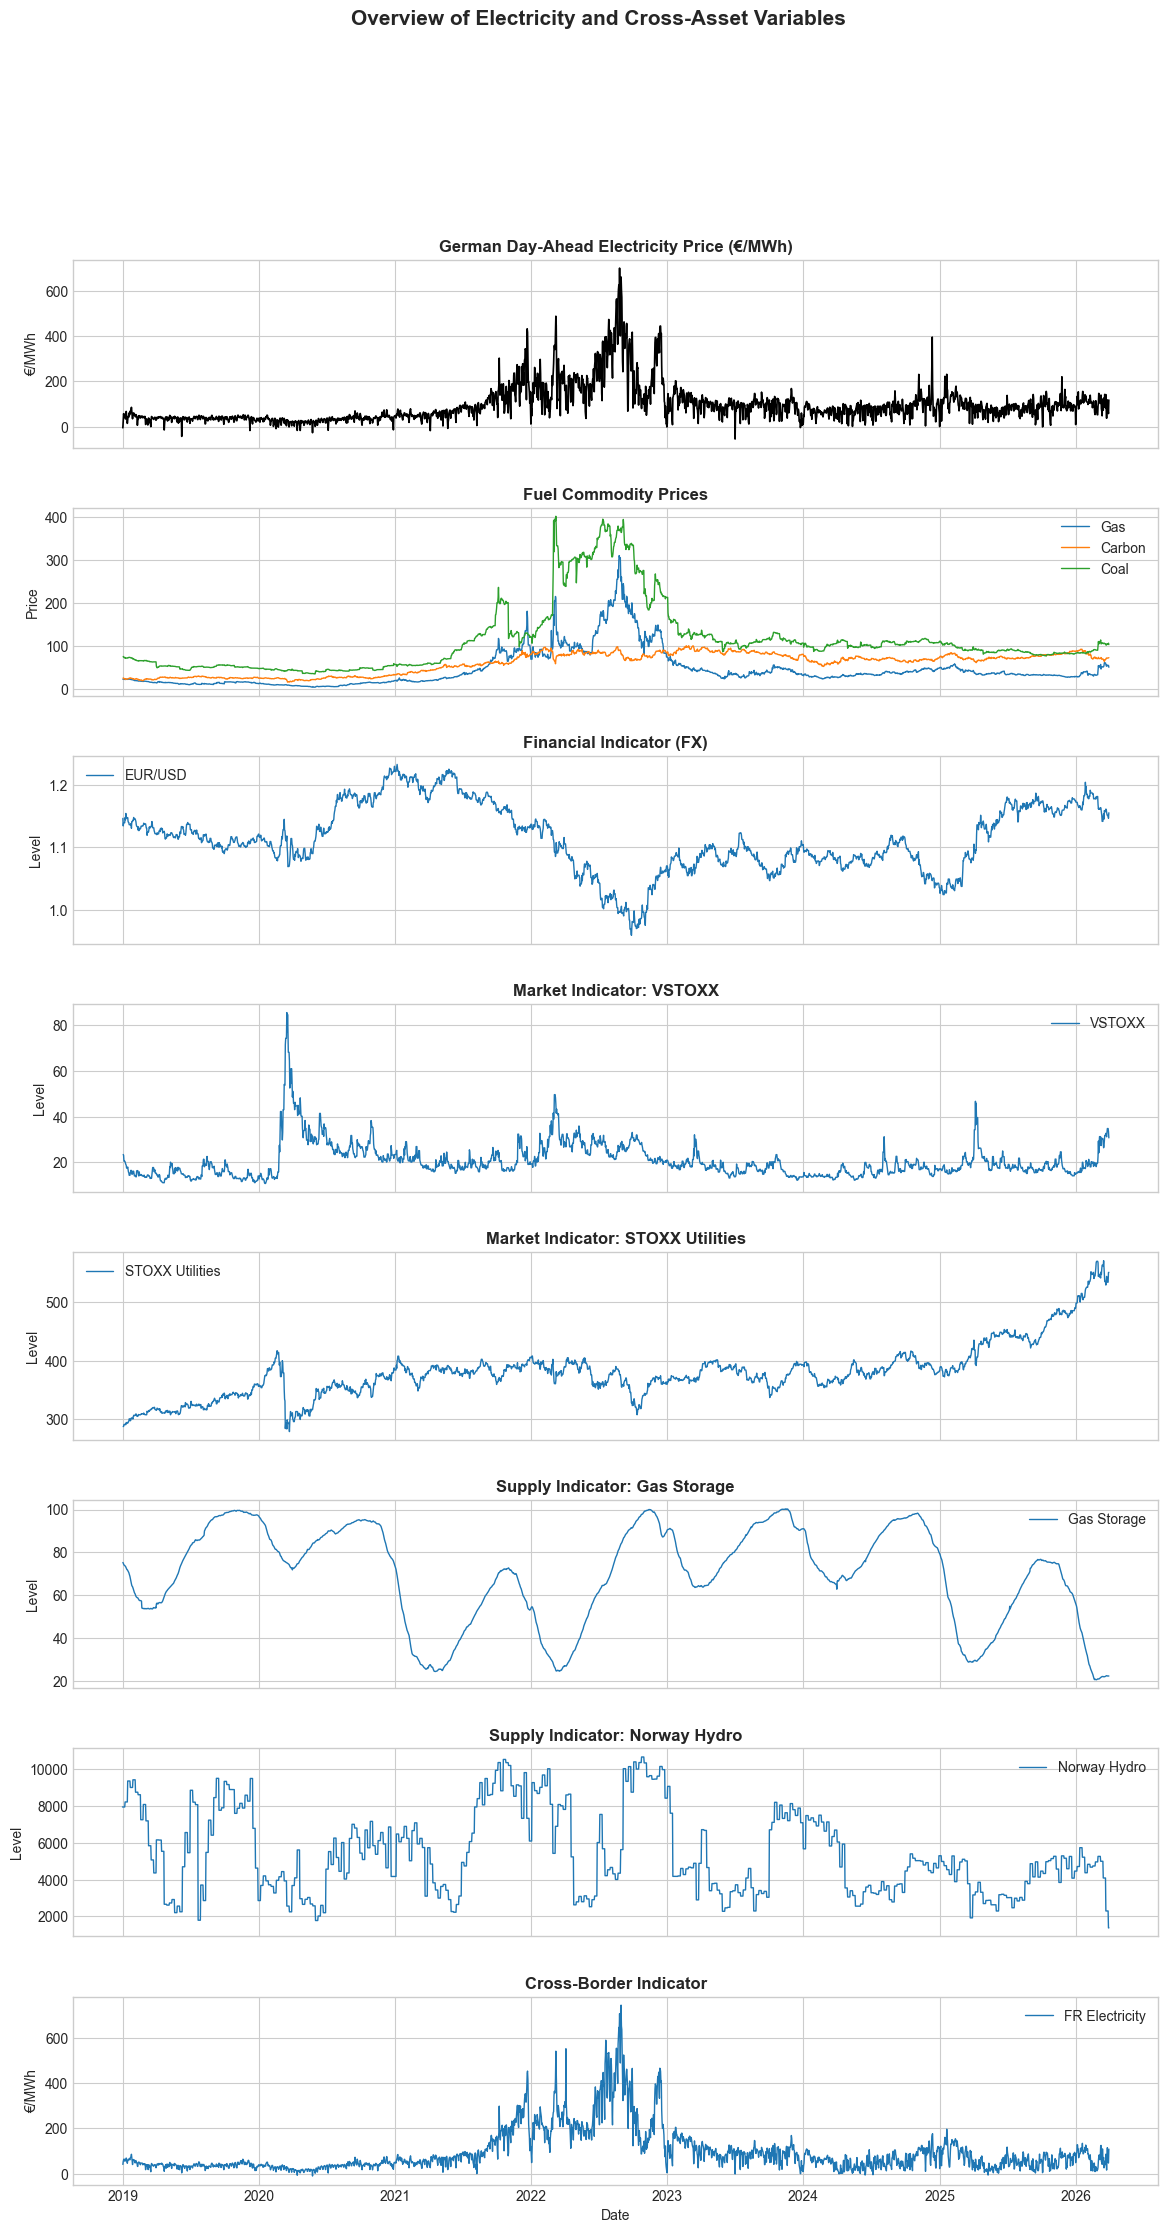

In [15]:
# -------------------------
# Simple Overview Plot (Descriptive Only)
# -------------------------

assets = {
    'Electricity':     price_history_electricity,
    'Gas':             price_history_gas_monthly1,
    'Carbon':          price_history_carbon,
    'Coal':            price_history_coal,
    'EUR/USD':         price_history_EURUSD,
    'Gas Storage':     price_history_gas_storage,
    'VSTOXX':          price_history_VSTOXX,
    'STOXX Utilities': price_history_STOXX_utilities,
    'FR Electricity':  fr_daily,
    'Norway Hydro':    norway_hydro,
}

price_levels = {}
for name, df in assets.items():
    price_levels[name] = df.sort_values('date').set_index('date')['price']

price_df = pd.DataFrame(price_levels)

fig, axes = plt.subplots(8, 1, figsize=(14, 25), sharex=True,
                         gridspec_kw={'hspace': 0.32})

# Panel 1 — Electricity
axes[0].plot(price_df.index, price_df['Electricity'], color='black', linewidth=1.2)
axes[0].set_title('German Day-Ahead Electricity Price (€/MWh)', fontweight='bold')
axes[0].set_ylabel('€/MWh')

# Panel 2 — Fuel commodities
for name in ['Gas', 'Carbon', 'Coal']:
    axes[1].plot(price_df.index, price_df[name], label=name, linewidth=1)
axes[1].set_title('Fuel Commodity Prices', fontweight='bold')
axes[1].set_ylabel('Price')
axes[1].legend()

# Panel 3 — Financial indicator
axes[2].plot(price_df.index, price_df['EUR/USD'], label='EUR/USD', linewidth=1)
axes[2].set_title('Financial Indicator (FX)', fontweight='bold')
axes[2].set_ylabel('Level')
axes[2].legend()

# Panel 4 — Market indicator: VSTOXX
axes[3].plot(price_df.index, price_df['VSTOXX'], label='VSTOXX', linewidth=1)
axes[3].set_title('Market Indicator: VSTOXX', fontweight='bold')
axes[3].set_ylabel('Level')
axes[3].legend()

# Panel 5 — Market indicator: STOXX Utilities
axes[4].plot(price_df.index, price_df['STOXX Utilities'], label='STOXX Utilities', linewidth=1)
axes[4].set_title('Market Indicator: STOXX Utilities', fontweight='bold')
axes[4].set_ylabel('Level')
axes[4].legend()

# Panel 6 — Supply indicator: Gas Storage
axes[5].plot(price_df.index, price_df['Gas Storage'], label='Gas Storage', linewidth=1)
axes[5].set_title('Supply Indicator: Gas Storage', fontweight='bold')
axes[5].set_ylabel('Level')
axes[5].legend()

# Panel 7 — Supply indicator: Norway Hydro
axes[6].plot(price_df.index, price_df['Norway Hydro'], label='Norway Hydro', linewidth=1)
axes[6].set_title('Supply Indicator: Norway Hydro', fontweight='bold')
axes[6].set_ylabel('Level')
axes[6].legend()

# Panel 8 — Cross-border indicator
axes[7].plot(price_df.index, price_df['FR Electricity'], label='FR Electricity', linewidth=1)
axes[7].set_title('Cross-Border Indicator', fontweight='bold')
axes[7].set_ylabel('€/MWh')
axes[7].legend()

axes[-1].set_xlabel('Date')
fig.suptitle('Overview of Electricity and Cross-Asset Variables', fontsize=15, fontweight='bold')

plt.tight_layout()
plt.show()

In [31]:
from pathlib import Path

statistic_assets = [
    ('Electricity (level)',           price_history_electricity['price']),
    ('Amprion Load Forecast Mean',       de_daily['Amprion Load Forecast Mean']),
    ('Amprion Load Forecast Min',        de_daily['Amprion Load Forecast Min']),
    ('Amprion Load Forecast Max',        de_daily['Amprion Load Forecast Max']),
    ('Amprion Load Forecast Peak Hour',  de_daily['Amprion Load Forecast Peak Hour']),
    ('PV+Wind Forecast Mean',            de_daily['PV+Wind Forecast Mean']),
    ('PV+Wind Forecast Min',             de_daily['PV+Wind Forecast Min']),
    ('PV+Wind Forecast Max',             de_daily['PV+Wind Forecast Max']),
    ('Gas (log-price)',               price_history_gas_monthly1['log_price']),
    ('Carbon (log-price)',            price_history_carbon['log_price']),
    ('Coal (log-price)',              price_history_coal['log_price']),
    ('Electricity (return)',          price_history_electricity['return']),
    ('Gas (log-return)',              price_history_gas_monthly1['return']),
    ('Carbon (log-return)',           price_history_carbon['return']),
    ('Coal (log-return)',             price_history_coal['return']),
    ('EUR/USD (return)',              price_history_EURUSD['return']),
    ('Gas Storage (Δ seasonal dev)',   price_history_gas_storage['return']),
    ('VSTOXX (return)',               price_history_VSTOXX['return']),
    ('STOXX Utilities (return)',      price_history_STOXX_utilities['return']),
    ('FR Electricity (lagged level)', fr_daily['feature']),
    ('Norway Hydro (seasonal dev)',   norway_hydro['return']),
]

summary_rows = []
for name, series in statistic_assets:
    s = series.dropna()
    summary_rows.append({
        'Variable': name,
        'Mean': s.mean(),
        'Std. Dev.': s.std(),
        'Min': s.min(),
        'Max': s.max(),
    })

variable_summary = pd.DataFrame(summary_rows)

output_dir = Path('output')
output_dir.mkdir(parents=True, exist_ok=True)
summary_path = output_dir / 'variable_summary.csv'
variable_summary.to_csv(summary_path, index=False)

print(f'Exported {summary_path}')
variable_summary

Exported output/variable_summary.csv


,Variable,Mean,Std. Dev.,Min,Max
0,Electricity (level),95.001202,85.215559,-53.870833,699.441667
1,Amprion Load Forecast Mean,11059.087956,1531.567266,6749.473990,15147.104698
2,Amprion Load Forecast Min,8986.311577,1252.854454,5407.915955,12756.550000
3,Amprion Load Forecast Max,12975.421468,1662.074907,8102.719250,17045.596500
4,Amprion Load Forecast Peak Hour,15.139781,4.927221,0.000000,22.000000
5,PV+Wind Forecast Mean,6639.608773,3001.866807,880.047668,16776.795560
6,PV+Wind Forecast Min,3539.460116,2785.541366,104.891923,14370.649417
7,PV+Wind Forecast Max,10657.026405,3652.417204,1624.902500,23138.528237
8,Gas (log-price),3.444078,0.840477,1.289233,5.739793
9,Carbon (log-price),3.971261,0.511489,2.727853,4.608564


## Metrics

In [16]:
# ADF
from statsmodels.tsa.stattools import adfuller

In [ ]:
adf_assets = [
    # Level variables — expected to be non-stationary (I(1))
    ('Electricity (level)',           price_history_electricity['price']),
    ('Gas (log-price)',               price_history_gas_monthly1['log_price']),
    ('Carbon (log-price)',            price_history_carbon['log_price']),
    ('Coal (log-price)',              price_history_coal['log_price']),
    ('Amprion Load Forecast Mean',       de_daily['Amprion Load Forecast Mean']),
    ('Amprion Load Forecast Min',        de_daily['Amprion Load Forecast Min']),
    ('Amprion Load Forecast Max',        de_daily['Amprion Load Forecast Max']),
    ('Amprion Load Forecast Peak Hour',  de_daily['Amprion Load Forecast Peak Hour']),
    ('PV+Wind Forecast Mean',            de_daily['PV+Wind Forecast Mean']),
    ('PV+Wind Forecast Min',             de_daily['PV+Wind Forecast Min']),
    ('PV+Wind Forecast Max',             de_daily['PV+Wind Forecast Max']),
    # Stationary / differenced features used in Granger
    ('Electricity (return)',          price_history_electricity['return']),
    ('Gas (log-return)',              price_history_gas_monthly1['return']),
    ('Carbon (log-return)',           price_history_carbon['return']),
    ('Coal (log-return)',             price_history_coal['return']),
    ('EUR/USD (return)',              price_history_EURUSD['return']),
    ('Gas Storage (Δ seasonal dev)',   price_history_gas_storage['return']),
    ('VSTOXX (return)',               price_history_VSTOXX['return']),
    ('STOXX Utilities (return)',      price_history_STOXX_utilities['return']),
    ('FR Electricity (lagged level)', fr_daily['feature']),
    ('Norway Hydro (seasonal dev)',   norway_hydro['return']),
]

def _adf_test(series, name=""):
    result = adfuller(series.dropna(), autolag='AIC')
    
    output = {
        "variable": name,
        "adf_stat": result[0],
        "p_value": result[1],
        "lags": result[2],
        "n_obs": result[3],
    }
    
    return output

In [29]:
for name, series in adf_assets:
    result = _adf_test(series.dropna(), name=name)
    print(f"{name}: stationary={'Yes' if result['p_value'] < 0.05 else 'No':<3}  "
          f"(p={result['p_value']:.4f})")

Electricity (level): stationary=Yes  (p=0.0104)
Gas (log-price): stationary=No   (p=0.6070)
Carbon (log-price): stationary=No   (p=0.5193)
Coal (log-price): stationary=No   (p=0.5856)
Electricity (return): stationary=Yes  (p=0.0000)
Gas (log-return): stationary=Yes  (p=0.0000)
Carbon (log-return): stationary=Yes  (p=0.0000)
Coal (log-return): stationary=Yes  (p=0.0000)
EUR/USD (return): stationary=Yes  (p=0.0000)
Gas Storage (Δ seasonal dev): stationary=Yes  (p=0.0000)
VSTOXX (return): stationary=Yes  (p=0.0000)
STOXX Utilities (return): stationary=Yes  (p=0.0000)
FR Electricity (lagged level): stationary=Yes  (p=0.0410)
Norway Hydro (seasonal dev): stationary=Yes  (p=0.0000)


In [20]:
# Granger Causality
from statsmodels.tsa.stattools import grangercausalitytests

In [21]:
def _return_series(obj, name, value_col="return"):
    if isinstance(obj, pd.DataFrame):
        return (
            obj[["date", value_col]]
            .dropna(subset=["date", value_col])
            .sort_values("date")
            .set_index("date")[value_col]
            .rename(name)
        )
    return obj.rename(name)


def _run_granger_raw(x, y, max_lag=5, x_col="return", y_col="return"):
    x_series = _return_series(x, "x", value_col=x_col)
    y_series = _return_series(y, "y", value_col=y_col)
    df = pd.concat([y_series, x_series], axis=1).dropna()

    if len(df) <= max_lag + 1:
        raise ValueError(f"Insufficient data for max_lag={max_lag}: {len(df)} observations")

    results = grangercausalitytests(df, maxlag=max_lag, verbose=False)
    return df, results


def granger_test(x, y, max_lag=5, x_col="return", y_col="return"):
    """
    Tests whether x Granger-causes y.
    DataFrames are aligned by date; Series are aligned by index.
    x_col / y_col: column to use when x or y is a DataFrame ('return', 'log_price', 'price').
    """
    _, results = _run_granger_raw(x, y, max_lag=max_lag, x_col=x_col, y_col=y_col)

    output = []
    for lag in range(1, max_lag + 1):
        # Extract regression results for this lag
        reg_res = results[lag][1][0]

        # The last coefficient corresponds to the highest lag of x
        # (i.e. the marginal effect of lag k, not cumulative)
        p_value = reg_res.pvalues[-1]
        output.append({"lag": lag, "p_value": p_value})

    return pd.DataFrame(output)


def granger_joint_test(x, y, max_lag=5, x_col="return", y_col="return"):
    """Joint significance test that lags 1..max_lag of x do not Granger-cause y."""
    df, results = _run_granger_raw(x, y, max_lag=max_lag, x_col=x_col, y_col=y_col)
    return {
        "joint_p_value": results[max_lag][0]["ssr_ftest"][1],
        "n_obs": len(df),
    }

In [22]:
# (label, x_df, x_col) — y is always electricity price level
granger_pairs = [
    # Returns-based (financial channel)
    ('Gas (log-return)',          price_history_gas_monthly1,    'return'),
    ('Carbon (log-return)',       price_history_carbon,          'return'),
    ('Coal (log-return)',         price_history_coal,            'return'),
    ('EUR/USD',                   price_history_EURUSD,          'return'),
    ('Gas Storage',               price_history_gas_storage,     'return'),
    ('VSTOXX',                    price_history_VSTOXX,          'return'),
    ('STOXX Utilities',           price_history_STOXX_utilities, 'return'),
    ('FR Electricity',            fr_daily,                      'feature'),
    ('Norway Hydro',              norway_hydro,                  'return'),
]

In [23]:
price = price_history_electricity['price']

volatility = price.rolling(7).std()
threshold = volatility.quantile(0.75)
price_history_electricity['vol_regime'] = np.where(
    volatility > threshold, 'high', 'low'
)

# Identify contiguous regime blocks (Granger needs consecutive observations)
regime_series = price_history_electricity['vol_regime']
block_id = (regime_series != regime_series.shift()).cumsum()
price_history_electricity['regime_block'] = block_id


def _contiguous_regime_panels(electricity_df, other_asset_df, regime,
                              other_name="other", min_block_len=30, value_col="return"):
    """Merge contiguous blocks of a given regime with the other asset.
    Prefer long contiguous runs, but fall back to all available matches if needed."""
    other = other_asset_df[["date", value_col]].rename(columns={value_col: other_name})
    regime_df = electricity_df[electricity_df["vol_regime"] == regime].copy()

    long_panels = []
    all_panels = []
    for _, block in regime_df.groupby("regime_block"):
        merged = (
            block[["date", "price"]]
            .rename(columns={"price": "elec"})
            .merge(other, on="date", how="inner")
            .dropna(subset=["elec", other_name])
            .sort_values("date")
        )
        if merged.empty:
            continue

        panel = merged.set_index("date")[["elec", other_name]]
        panel.index = pd.to_datetime(panel.index)
        all_panels.append(panel)
        if len(merged) >= min_block_len:
            long_panels.append(panel)

    if long_panels:
        panel = pd.concat(long_panels).sort_index()
        return panel[~panel.index.duplicated()]
    if all_panels:
        panel = pd.concat(all_panels).sort_index()
        return panel[~panel.index.duplicated()]
    return pd.DataFrame(columns=["elec", other_name])


# Regime-specific Granger tests are conducted on concatenated segments of similar
# volatility regimes. While this approach does not strictly preserve continuous time
# dynamics, it provides indicative evidence of regime-dependent predictability.
def granger_by_regime(
    electricity_df,
    other_asset_df,
    other_name="other",
    max_lag=5,
    min_block_len=30,
    value_col="return",
    verbose=False,
):
    data_high = _contiguous_regime_panels(
        electricity_df, other_asset_df, "high", other_name, min_block_len, value_col
    )
    data_low = _contiguous_regime_panels(
        electricity_df, other_asset_df, "low", other_name, min_block_len, value_col
    )

    results = {}
    for label, data in [("high_vol", data_high), ("low_vol", data_low)]:
        regime_label = "High volatility" if label == "high_vol" else "Normal volatility"
        if len(data) > max_lag + 1:
            data = data.sort_index()
            fwd = granger_test(data[other_name], data["elec"], max_lag=max_lag)
            rev = granger_test(data["elec"], data[other_name], max_lag=max_lag)
            fwd_joint = granger_joint_test(data[other_name], data["elec"], max_lag=max_lag)
            rev_joint = granger_joint_test(data["elec"], data[other_name], max_lag=max_lag)
            results[label] = {
                "forward": fwd,
                "reverse": rev,
                "forward_joint_p_value": fwd_joint["joint_p_value"],
                "reverse_joint_p_value": rev_joint["joint_p_value"],
            }
            if verbose:
                print(f"{regime_label} — {other_name} → elec:\n", fwd, "\n")
                print(f"{regime_label} — {other_name} → elec joint (lags 1..{max_lag}): {fwd_joint['joint_p_value']:.6g}\n")
                print(f"{regime_label} — elec → {other_name}:\n", rev, "\n")
                print(f"{regime_label} — elec → {other_name} joint (lags 1..{max_lag}): {rev_joint['joint_p_value']:.6g}\n")
        else:
            results[label] = f"Insufficient data ({len(data)} obs)"
            if verbose:
                print(f"{regime_label} — {other_name}: Insufficient data ({len(data)} obs)\n")

    return results

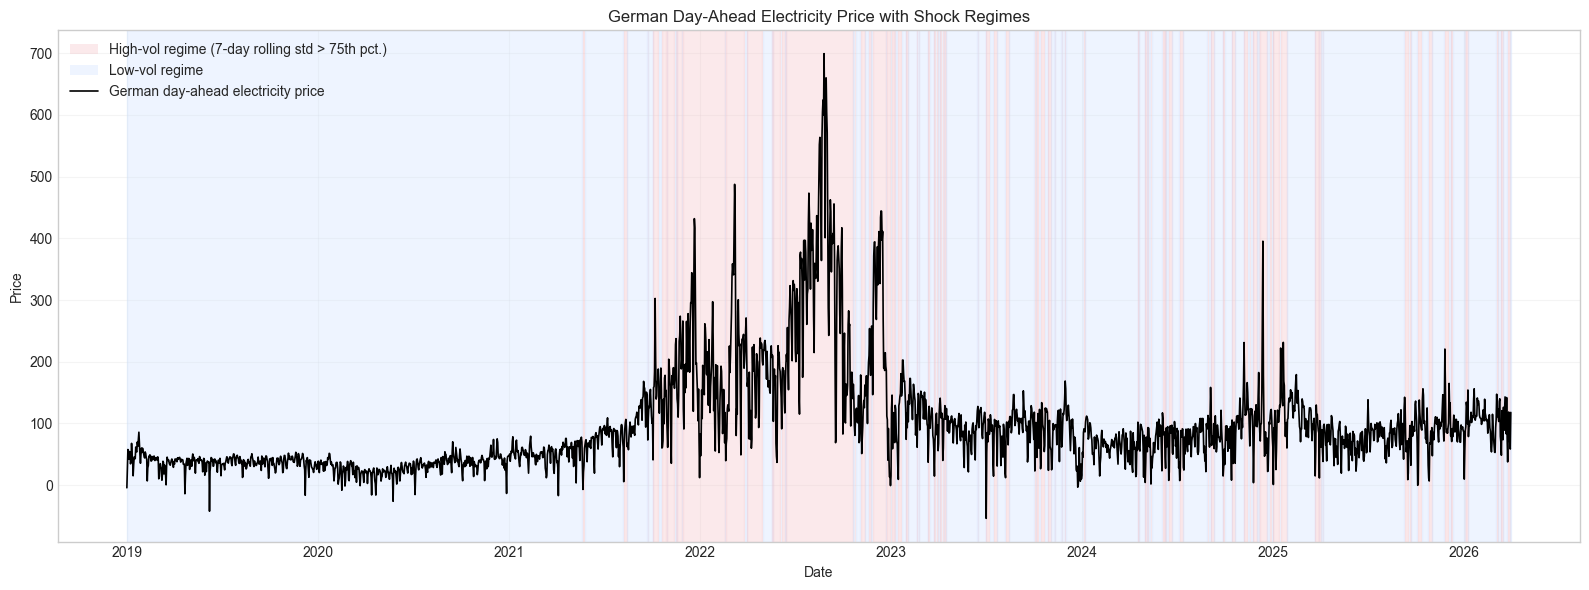

In [32]:
# Regime visualization on German day-ahead electricity price
regime_plot_df = (
    price_history_electricity[["date", "price", "vol_regime"]]
    .dropna(subset=["date", "price", "vol_regime"])
    .sort_values("date")
    .copy()
)

regime_plot_df["regime_block"] = (
    regime_plot_df["vol_regime"] != regime_plot_df["vol_regime"].shift()
).cumsum()

fig, ax = plt.subplots(figsize=(16, 6))

for _, block in regime_plot_df.groupby("regime_block"):
    regime = block["vol_regime"].iloc[0]
    color = "#f5c2c7" if regime == "high" else "#cfe2ff"
    ax.axvspan(block["date"].iloc[0], block["date"].iloc[-1], color=color, alpha=0.35)

ax.plot(
    regime_plot_df["date"],
    regime_plot_df["price"],
    color="black",
    linewidth=1.2,
    label="German day-ahead electricity price",
)

from matplotlib.patches import Patch
legend_handles = [
    Patch(facecolor="#f5c2c7", edgecolor="none", alpha=0.35, label="High-vol regime (7-day rolling std > 75th pct.)"),
    Patch(facecolor="#cfe2ff", edgecolor="none", alpha=0.35, label="Low-vol regime"),
]

ax.set_title("German Day-Ahead Electricity Price with Shock Regimes")
ax.set_xlabel("Date")
ax.set_ylabel("Price")
ax.legend(handles=legend_handles + [ax.lines[0]], loc="upper left")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

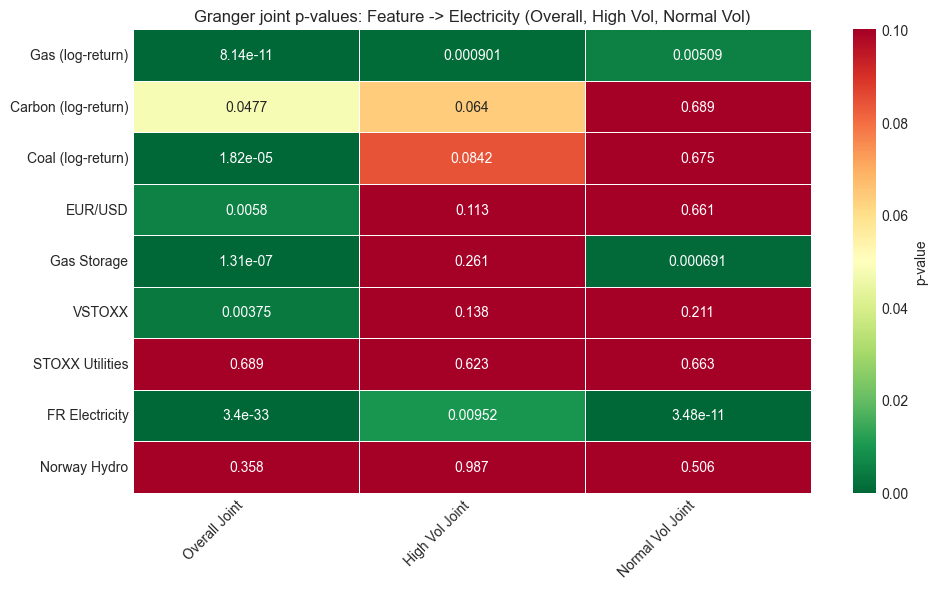

In [25]:
# Consolidated joint p-value overview (feature -> electricity)
max_lag = 5
rows = []

for feature, asset_df, x_col in granger_pairs:
    row = {"Feature": feature}

    # Overall sample (joint across lags 1..max_lag)
    row["Overall Joint"] = granger_joint_test(
        asset_df,
        price_history_electricity,
        max_lag=max_lag,
        x_col=x_col,
        y_col="price",
    )["joint_p_value"]

    # Regime-specific joint tests only (no lag/day-specific columns)
    for regime_value, regime_prefix in [("high", "High Vol"), ("low", "Normal Vol")]:
        panel = _contiguous_regime_panels(
            price_history_electricity,
            asset_df,
            regime=regime_value,
            other_name="feature",
            min_block_len=30,
            value_col=x_col,
        )

        if len(panel) > max_lag + 1:
            joint_p = granger_joint_test(panel["feature"], panel["elec"], max_lag=max_lag)["joint_p_value"]
            row[f"{regime_prefix} Joint"] = joint_p
        else:
            row[f"{regime_prefix} Joint"] = np.nan

    rows.append(row)

pvalue_overview = pd.DataFrame(rows)

ordered_cols = ["Feature", "Overall Joint", "High Vol Joint", "Normal Vol Joint"]
pvalue_overview = pvalue_overview[ordered_cols]
p_cols = [c for c in pvalue_overview.columns if c != "Feature"]

heatmap_data = pvalue_overview.set_index("Feature")[p_cols]

plt.figure(figsize=(10, max(6, 0.55 * len(heatmap_data))))
sns.heatmap(
    heatmap_data,
    cmap="RdYlGn_r",
    vmin=0,
    vmax=0.1,
    annot=True,
    fmt=".3g",
    linewidths=0.4,
    linecolor="white",
    cbar_kws={"label": "p-value"},
)
plt.title("Granger joint p-values: Feature -> Electricity (Overall, High Vol, Normal Vol)")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Conclusion

The Granger causality results indicate that predictive power is concentrated in a small subset of variables. Gas price changes (log-returns) and French electricity prices show consistent and robust significance across specifications, suggesting strong short-run and cross-market effects. Coal returns exhibit some predictive power in the overall sample but are less stable across regimes. In contrast, carbon returns, financial indicators (EUR/USD, VSTOXX, STOXX Utilities), and hydro variables do not display consistent significance and therefore appear to add limited incremental forecasting value. Gas storage shows some relevance in specific regimes but is not robust overall.

Overall, the evidence points to a sparse predictive structure dominated by key energy market variables rather than a broad set of cross-asset signals.

## CSV Export

In [26]:
from pathlib import Path

# -------------------------
# CSV exports for Model 1-5
# -------------------------

output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)

# Base DE dataframe (Model 1)
de_model_base = de_daily.copy()
de_model_base["date"] = pd.to_datetime(de_model_base["datetime"]).dt.normalize()

def _series_from_df(df, col, name):
    return (
        df[["date", col]]
        .dropna(subset=["date"])
        .drop_duplicates(subset=["date"], keep="last")
        .rename(columns={col: name})
    )

# Source features from already prepared notebook datasets
feature_tables = [
    _series_from_df(price_history_gas_monthly1, "return", "gas_return"),
    _series_from_df(price_history_coal, "return", "coal_return"),
    _series_from_df(fr_daily, "feature", "fr_lagged"),
    _series_from_df(price_history_gas_storage, "price", "gas_storage"),
    _series_from_df(price_history_EURUSD, "return", "eurusd_return"),
    _series_from_df(price_history_VSTOXX, "return", "vstoxx_return"),
    _series_from_df(price_history_electricity, "price", "electricity_price"),
]

for ft in feature_tables:
    de_model_base = de_model_base.merge(ft, on="date", how="left")

# Electricity volatility (7-day rolling std of DE electricity level)
de_model_base["electricity_volatility"] = de_model_base["electricity_price"].rolling(7).std()

# Interaction terms
# Model 3
de_model_base["gas_x_electricity_volatility"] = (
    de_model_base["gas_return"] * de_model_base["electricity_volatility"]
)
de_model_base["fr_x_electricity_volatility"] = (
    de_model_base["fr_lagged"] * de_model_base["electricity_volatility"]
)

# Model 4
de_model_base["gas_return_x_gas_storage"] = (
    de_model_base["gas_return"] * de_model_base["gas_storage"]
)

# Model 5
de_model_base["vstoxx_x_electricity_volatility"] = (
    de_model_base["vstoxx_return"] * de_model_base["electricity_volatility"]
)


def _add_lags(df, cols, max_lag=5):
    out = df.copy()
    for col in cols:
        for lag in range(1, max_lag + 1):
            out[f"{col}_lag{lag}"] = out[col].shift(lag)
    return out

# Cumulative model definitions
model_added_terms = {
    "model_1_base": [],
    "model_2": [
        "gas_return",
        "coal_return",
        "fr_lagged",
    ],
    "model_3": [
        "gas_return",
        "coal_return",
        "fr_lagged",
        "electricity_volatility",
        "gas_x_electricity_volatility",
        "fr_x_electricity_volatility",
    ],
    "model_4": [
        "gas_return",
        "coal_return",
        "fr_lagged",
        "electricity_volatility",
        "gas_x_electricity_volatility",
        "fr_x_electricity_volatility",
        "gas_storage",
        "gas_return_x_gas_storage",
    ],
    "model_5": [
        "gas_return",
        "coal_return",
        "fr_lagged",
        "electricity_volatility",
        "gas_x_electricity_volatility",
        "fr_x_electricity_volatility",
        "gas_storage",
        "gas_return_x_gas_storage",
        "eurusd_return",
        "vstoxx_return",
        "vstoxx_x_electricity_volatility",
    ],
}

base_cols = [
    "datetime",
    "Price",
    "Amprion Load Forecast Mean",
    "Amprion Load Forecast Min",
    "Amprion Load Forecast Max",
    "Amprion Load Forecast Peak Hour",
    "PV+Wind Forecast Mean",
    "PV+Wind Forecast Min",
    "PV+Wind Forecast Max",
]

for model_name, added_cols in model_added_terms.items():
    df_model = de_model_base[base_cols + added_cols].copy()
    if added_cols:
        df_model = _add_lags(df_model, added_cols, max_lag=5)

    out_path = output_dir / f"DE_{model_name}.csv"
    df_model.to_csv(out_path, index=False)

print("CSV export finished:")
for model_name in model_added_terms:
    print(f"- {output_dir / f'DE_{model_name}.csv'}")

CSV export finished:
- output/DE_model_1_base.csv
- output/DE_model_2.csv
- output/DE_model_3.csv
- output/DE_model_4.csv
- output/DE_model_5.csv
